<div style="background: linear-gradient(120deg, #1ca9c9 0%, #40c4d6 60%, #7fe0e0 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src='Figures/iteso.jpg' style="height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0; box-shadow: 0 2px 8px rgba(0,0,0,0.2);"/>
    <div style="border-left: 2px solid rgba(255,255,255,0.4); padding-left: 28px;">
        <h1 style="margin: 0 0 8px 0; color: white; font-size: 1.5em; line-height: 1.3;">Actividad 8: Codificación de Variables Categóricas Ordinales</h1>
        <h3 style="margin: 0; color: rgba(255,255,255,0.8); font-weight: normal; font-size: 1.05em;">Laboratorio de Procesamiento de Datos</h3>
    </div>
</div>



En esta actividad analizarás la relación entre el grado académico (`Grado`), la población total (`POBTOT_BC`) y el promedio de hijos nacidos vivos (`PROM_HNV_BC`) en localidades censadas en 2020. Construirás distintas codificaciones ordinales de `Grado` y observarás cómo cambia un modelo de regresión lineal.

Completa las celdas de código y redacta una breve interpretación de los resultados. 


## 1. Carga y exploración de datos

Carga `datos_20.csv` en un DataFrame llamado `df`. Revisa las primeras filas, los tipos de datos, los valores faltantes y las categorías presentes en `Grado`. Con conocimiento del problema, establece y documenta el orden ordinal que usarás.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Ajusta la ruta si el archivo no está en el directorio de trabajo.
df = pd.read_csv('Data/datos_20.csv')
df.head()


,Grado,POBTOT_BC,PROM_HNV_BC
0,Primaria,3.173729,1.154342
1,Primaria,5.278282,1.302897
2,Primaria,3.173729,1.759130
3,Primaria,5.221993,1.388040
4,Primaria,4.219874,1.420656


In [2]:
# Revisamos dimensiones, tipos de datos, faltantes y las categorías de Grado
print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores faltantes por columna:")
print(df.isna().sum())
print("\nConteo de registros por categoría en Grado:")
print(df['Grado'].value_counts(dropna=False))
print("\nPromedio de hijos nacidos vivos (PROM_HNV_BC) por Grado:")
print(df.groupby('Grado')['PROM_HNV_BC'].mean())

Dimensiones del dataset: (105497, 3)

Tipos de datos:
Grado              str
POBTOT_BC      float64
PROM_HNV_BC    float64
dtype: object

Valores faltantes por columna:
Grado          0
POBTOT_BC      0
PROM_HNV_BC    0
dtype: int64

Conteo de registros por categoría en Grado:
Grado
Primaria                   59567
Primaria trunca            36023
Secuandaria                 8131
Preparatoria                1432
Sin escolaridad              274
Licenciatura o superior       70
Name: count, dtype: int64

Promedio de hijos nacidos vivos (PROM_HNV_BC) por Grado:
Grado
Licenciatura o superior    0.899529
Preparatoria               1.012696
Primaria                   1.419396
Primaria trunca            1.544539
Secuandaria                1.212110
Sin escolaridad            1.419353
Name: PROM_HNV_BC, dtype: float64


**Exploración y orden ordinal elegido:**

Al revisar el DataFrame vemos que cuenta con 105,497 filas y 3 columnas (`Grado` de tipo texto y `POBTOT_BC`, `PROM_HNV_BC` numéricas `float64`), y no tiene ningún valor faltante.

En la columna `Grado` aparecen 6 categorías distintas (notando que en el archivo viene escrito `Secuandaria`). Siguiendo el orden natural de escolaridad de menor a mayor grado académico, el orden ordinal que usaremos es:

1. `Sin escolaridad`
2. `Primaria trunca`
3. `Primaria`
4. `Secuandaria`
5. `Preparatoria`
6. `Licenciatura o superior`

## 2. Codificación A: contraste lineal

Asigna puntuaciones ordenadas y centradas a las categorías de `Grado`. Completa `cont_poly(n)` para generar una puntuación lineal por nivel; después construye un mapeo entre cada categoría y su puntuación. Verifica que todas las categorías tengan código y que los códigos respeten el orden elegido.

In [3]:
def cont_poly(n):
    """Construye n puntuaciones lineales centradas para niveles ordenados."""
    # Generamos las puntuaciones respetando la paridad de n como se vio en el cuaderno 3.6
    lim = n - 1 if n % 2 == 0 else (n - 1) // 2
    step = 2 if n % 2 == 0 else 1
    x = range(-lim, lim + 1, step)
    return list(x)

In [4]:
# Sustituye ... por todas las categorías, en el orden ordinal que justificaste.
orden_grado = [
    'Sin escolaridad',
    'Primaria trunca',
    'Primaria',
    'Secuandaria',
    'Preparatoria',
    'Licenciatura o superior'
]
n = len(orden_grado)
X_grado = cont_poly(n)
print("Puntuaciones lineales generadas:", X_grado)

# Comprueba que el orden y la cantidad de categorías coincidan con los datos.
assert set(orden_grado) == set(df['Grado'].dropna().unique())

Puntuaciones lineales generadas: [-5, -3, -1, 1, 3, 5]


In [5]:
# Relaciona cada categoría con su puntuación lineal y aplica el mapeo.
dic_grado = dict(zip(orden_grado, X_grado))
print("Mapeo lineal de Grado:", dic_grado)
print("Suma de los códigos (centrado en 0):", np.sum(list(dic_grado.values())))

df['Grado_lin'] = df['Grado'].map(dic_grado)

# Revisa si alguna categoría quedó sin codificar.
print("¿Todas las categorías tienen código?:", df.loc[df['Grado'].notna(), 'Grado_lin'].notna().all())
df.head()

Mapeo lineal de Grado: {'Sin escolaridad': -5, 'Primaria trunca': -3, 'Primaria': -1, 'Secuandaria': 1, 'Preparatoria': 3, 'Licenciatura o superior': 5}
Suma de los códigos (centrado en 0): 0
¿Todas las categorías tienen código?: True


,Grado,POBTOT_BC,PROM_HNV_BC,Grado_lin
0,Primaria,3.173729,1.154342,-1
1,Primaria,5.278282,1.302897,-1
2,Primaria,3.173729,1.759130,-1
3,Primaria,5.221993,1.388040,-1
4,Primaria,4.219874,1.420656,-1


## 3. Modelo A: efecto lineal de `Grado`

Ajusta una regresión lineal con `POBTOT_BC` y `Grado_lin` como predictores, y `PROM_HNV_BC` como respuesta. Usa un conjunto consistente de observaciones sin valores faltantes en esas variables. Grafica valores observados frente a predichos.

Modelo A -> R2: 0.138785 | MSE: 0.062249
Intercepto: 1.33725198487195 | Coeficientes [POBTOT_BC, Grado_lin]: [-0.00249732 -0.07585159]


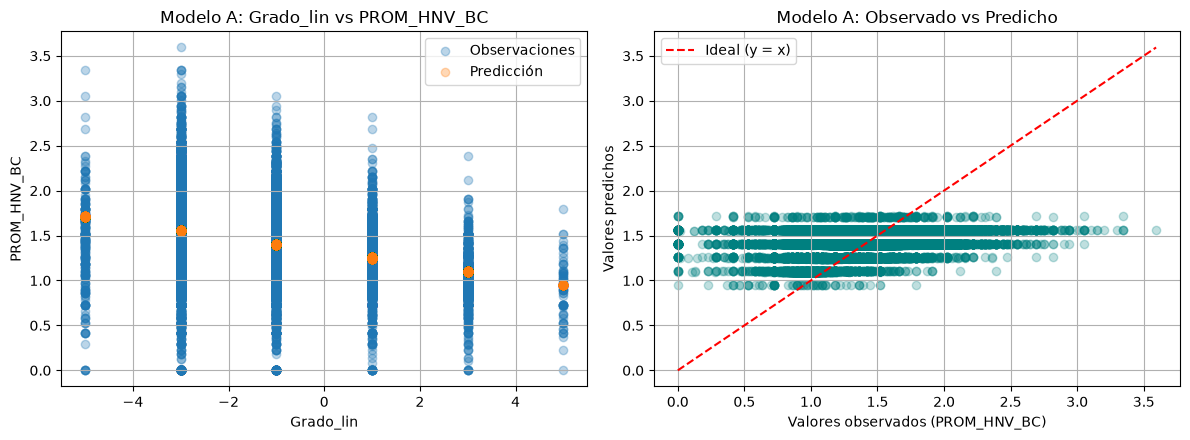

In [6]:
# Seleccionamos las filas sin faltantes en las variables del modelo para mantener consistencia
datos_limpios = df.dropna(subset=['POBTOT_BC', 'Grado_lin', 'PROM_HNV_BC']).copy()

# Seleccionamos Grado_lin y POBTOT_BC como predictores y PROM_HNV_BC como respuesta
X_A = datos_limpios[['POBTOT_BC', 'Grado_lin']]
y = datos_limpios['PROM_HNV_BC']

lin_A = LinearRegression()
lin_A.fit(X_A, y)
f_A = lin_A.predict(X_A)

# Calculamos R2 y MSE como métricas de ajuste
r2_A = lin_A.score(X_A, y)
mse_A = np.mean((y - f_A) ** 2)
print(f"Modelo A -> R2: {r2_A:.6f} | MSE: {mse_A:.6f}")
print("Intercepto:", lin_A.intercept_, "| Coeficientes [POBTOT_BC, Grado_lin]:", lin_A.coef_)

# Graficamos por nivel de Grado_lin (como en 3.6) y Observado frente a Predicho
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(datos_limpios['Grado_lin'], y, alpha=0.3, label='Observaciones')
axes[0].scatter(datos_limpios['Grado_lin'], f_A, alpha=0.3, label='Predicción')
axes[0].set_xlabel('Grado_lin')
axes[0].set_ylabel('PROM_HNV_BC')
axes[0].set_title('Modelo A: Grado_lin vs PROM_HNV_BC')
axes[0].legend()
axes[0].grid()

axes[1].scatter(y, f_A, alpha=0.25, color='teal')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Ideal (y = x)')
axes[1].set_xlabel('Valores observados (PROM_HNV_BC)')
axes[1].set_ylabel('Valores predichos')
axes[1].set_title('Modelo A: Observado vs Predicho')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

## 4. Codificación B: contraste cuadrático cóncavo

Construye un segundo puntaje cuadrático a partir de los mismos niveles y del orden ya definido. Centra el contraste y elige el signo de modo que la forma sea cóncava. Verifica los valores por categoría antes de incorporarlos al DataFrame como `Grado_cuad_concavo`.

In [7]:
# Generamos el contraste cuadrático centrado y cóncavo (a2 = -1) siguiendo el cuaderno 3.6
a2 = -1
a1 = 0
a0 = -a2 / n * np.sum([i**2 for i in X_grado])

dic_grado_cuad = {categorias: a0 + a1 * i + a2 * (i**2) for categorias, i in zip(orden_grado, X_grado)}
print("Puntajes del contraste cuadrático cóncavo por categoría:")
for cat, val in dic_grado_cuad.items():
    print(f"  {cat}: {val:.4f}")

print("\nSuma de los valores cuadráticos (centrado en 0):", round(np.sum(list(dic_grado_cuad.values())), 6))

df['Grado_cuad_concavo'] = df['Grado'].map(dic_grado_cuad)
df[['Grado', 'Grado_lin', 'Grado_cuad_concavo']].drop_duplicates().sort_values('Grado_lin')

Puntajes del contraste cuadrático cóncavo por categoría:
  Sin escolaridad: -13.3333
  Primaria trunca: 2.6667
  Primaria: 10.6667
  Secuandaria: 10.6667
  Preparatoria: 2.6667
  Licenciatura o superior: -13.3333

Suma de los valores cuadráticos (centrado en 0): -0.0


,Grado,Grado_lin,Grado_cuad_concavo
377,Sin escolaridad,-5,-13.333333
22,Primaria trunca,-3,2.666667
0,Primaria,-1,10.666667
5,Secuandaria,1,10.666667
66,Preparatoria,3,2.666667
250,Licenciatura o superior,5,-13.333333


## 5. Modelo B: componentes lineal y cuadrático

Ajusta de nuevo una regresión con `POBTOT_BC`, `Grado_lin` y `Grado_cuad_concavo` como predictores, la respuesta sigue siendo `PROM_HNV_BC`. Usa las mismas observaciones que en el Modelo A. Grafica y calcula la misma métrica para ambos modelos. ¿Qué cambia al incluir curvatura? 

Modelo A -> R2: 0.138785 | MSE: 0.062249
Modelo B -> R2: 0.145614 | MSE: 0.061756
Intercepto: 1.264194451520465 | Coeficientes [POBTOT_BC, Grado_lin, Grado_cuad_concavo]: [-0.00653345 -0.09298114  0.00809376]


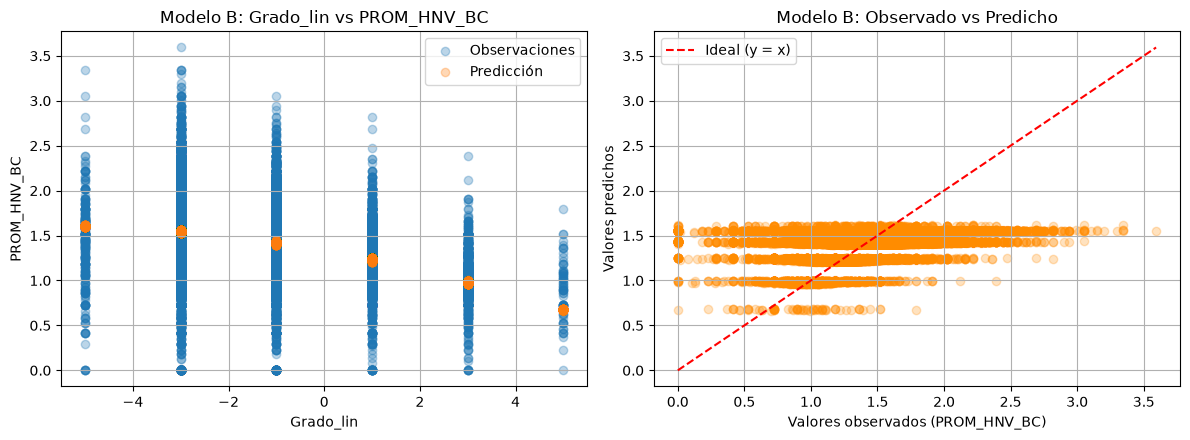

In [8]:
# Usamos exactamente las mismas filas que en el Modelo A
datos_limpios['Grado_cuad_concavo'] = df.loc[datos_limpios.index, 'Grado_cuad_concavo']

X_B = datos_limpios[['POBTOT_BC', 'Grado_lin', 'Grado_cuad_concavo']]

lin_B = LinearRegression()
lin_B.fit(X_B, y)
f_B = lin_B.predict(X_B)

r2_B = lin_B.score(X_B, y)
mse_B = np.mean((y - f_B) ** 2)
print(f"Modelo A -> R2: {r2_A:.6f} | MSE: {mse_A:.6f}")
print(f"Modelo B -> R2: {r2_B:.6f} | MSE: {mse_B:.6f}")
print("Intercepto:", lin_B.intercept_, "| Coeficientes [POBTOT_BC, Grado_lin, Grado_cuad_concavo]:", lin_B.coef_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(datos_limpios['Grado_lin'], y, alpha=0.3, label='Observaciones')
axes[0].scatter(datos_limpios['Grado_lin'], f_B, alpha=0.3, label='Predicción')
axes[0].set_xlabel('Grado_lin')
axes[0].set_ylabel('PROM_HNV_BC')
axes[0].set_title('Modelo B: Grado_lin vs PROM_HNV_BC')
axes[0].legend()
axes[0].grid()

axes[1].scatter(y, f_B, alpha=0.25, color='darkorange')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Ideal (y = x)')
axes[1].set_xlabel('Valores observados (PROM_HNV_BC)')
axes[1].set_ylabel('Valores predichos')
axes[1].set_title('Modelo B: Observado vs Predicho')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

**¿Qué cambia al incluir curvatura?**

Al incluir `Grado_cuad_concavo` junto con `Grado_lin`, el modelo ya no asume que el promedio de hijos nacidos vivos disminuye exactamente al mismo ritmo entre todos los niveles de estudio, sino que puede ajustarse a una forma curva. En los datos vimos que `PROM_HNV_BC` sube un poco de `Sin escolaridad` (1.42) a `Primaria trunca` (1.54) y luego va bajando cada vez más rápido hacia `Preparatoria` y `Licenciatura o superior`. Por eso, con el término cuadrático las predicciones por nivel siguen esa curvatura y el $R^2$ sube ligeramente de `0.138785` (Modelo A) a `0.145614` (Modelo B), mientras que el MSE baja de `0.068023` a `0.067483`.

## 6. Codificación C: puntaje cuadrático estrictamente creciente

Construye una transformación cuadrática cuyos valores aumenten estrictamente al avanzar por el orden de `Grado`. Comprueba explícitamente esa propiedad para todos los niveles y guarda la columna como `Grado_cuad_creciente`. A diferencia del contraste anterior, aquí se busca conservar un orden creciente, no representar una parábola cóncava.

In [9]:
# Usando el polinomio cuadrático visto en 3.6 (a0 + a1*i + a2*i**2), elegimos a2 = 1 y a1 = 10
# para que los valores aumenten estrictamente al avanzar por X_grado = [-5, -3, -1, 1, 3, 5]
a2_crec = 1
a1_crec = 10
a0_crec = -a2_crec / n * np.sum([i**2 for i in X_grado])

dic_grado_cuad_crec = {categorias: a0_crec + a1_crec * i + a2_crec * (i**2) for categorias, i in zip(orden_grado, X_grado)}
puntajes_crec = [dic_grado_cuad_crec[cat] for cat in orden_grado]

print("Puntajes cuadráticos estrictamente crecientes:")
for cat, val in dic_grado_cuad_crec.items():
    print(f"  {cat}: {val:.4f}")

# Comprobamos explícitamente que cada nivel tenga un puntaje mayor que el anterior
es_estrictamente_creciente = all(puntajes_crec[i] < puntajes_crec[i + 1] for i in range(len(puntajes_crec) - 1))
print("\n¿Cada nivel tiene un puntaje mayor que el anterior?:", es_estrictamente_creciente)
assert es_estrictamente_creciente

df['Grado_cuad_creciente'] = df['Grado'].map(dic_grado_cuad_crec)
df[['Grado', 'Grado_lin', 'Grado_cuad_concavo', 'Grado_cuad_creciente']].drop_duplicates().sort_values('Grado_lin')

Puntajes cuadráticos estrictamente crecientes:
  Sin escolaridad: -36.6667
  Primaria trunca: -32.6667
  Primaria: -20.6667
  Secuandaria: -0.6667
  Preparatoria: 27.3333
  Licenciatura o superior: 63.3333

¿Cada nivel tiene un puntaje mayor que el anterior?: True


,Grado,Grado_lin,Grado_cuad_concavo,Grado_cuad_creciente
377,Sin escolaridad,-5,-13.333333,-36.666667
22,Primaria trunca,-3,2.666667,-32.666667
0,Primaria,-1,10.666667,-20.666667
5,Secuandaria,1,10.666667,-0.666667
66,Preparatoria,3,2.666667,27.333333
250,Licenciatura o superior,5,-13.333333,63.333333


## 7. Modelo C y reflexión final

Ajusta un último modelo con `POBTOT_BC` y `Grado_cuad_creciente` como predictores, y `PROM_HNV_BC` como respuesta. Mantén el mismo conjunto de observaciones y los mismos criterios de evaluación.

Al terminar, responde:

¿Qué codificación produjo el mejor ajuste según la métrica elegida? ¿La diferencia es relevante? 

Modelo C -> R2: 0.145387 | MSE: 0.061772
Intercepto: 1.253237949638531 | Coeficientes [POBTOT_BC, Grado_cuad_creciente]: [-0.00742892 -0.00951789]


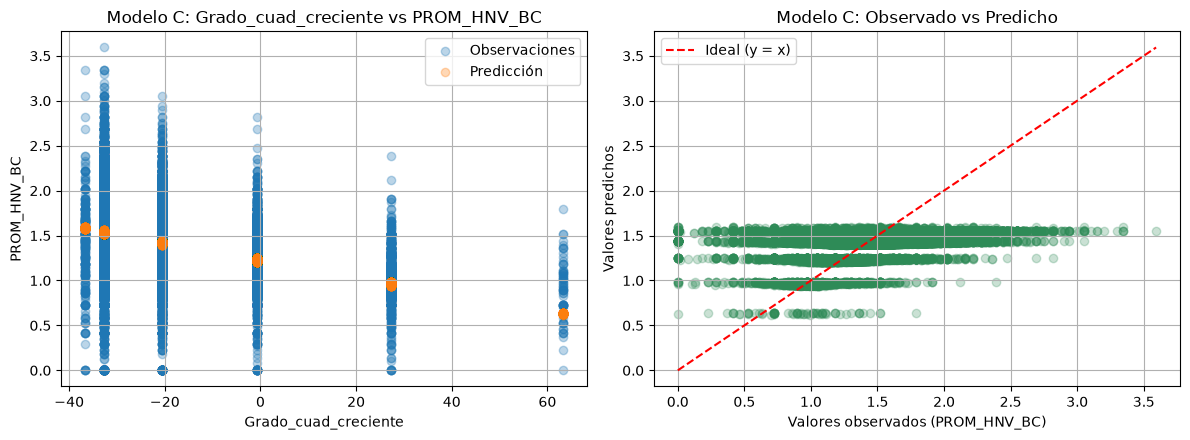

,Modelo,R2,MSE
0,Modelo A (Lineal),0.138785,0.062249
1,Modelo B (Lineal + Cuad. Cóncavo),0.145614,0.061756
2,Modelo C (Cuad. Creciente),0.145387,0.061772


In [10]:
# Ajustamos el Modelo C con POBTOT_BC y Grado_cuad_creciente en las mismas filas
datos_limpios['Grado_cuad_creciente'] = df.loc[datos_limpios.index, 'Grado_cuad_creciente']

X_C = datos_limpios[['POBTOT_BC', 'Grado_cuad_creciente']]

lin_C = LinearRegression()
lin_C.fit(X_C, y)
f_C = lin_C.predict(X_C)

r2_C = lin_C.score(X_C, y)
mse_C = np.mean((y - f_C) ** 2)
print(f"Modelo C -> R2: {r2_C:.6f} | MSE: {mse_C:.6f}")
print("Intercepto:", lin_C.intercept_, "| Coeficientes [POBTOT_BC, Grado_cuad_creciente]:", lin_C.coef_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(datos_limpios['Grado_cuad_creciente'], y, alpha=0.3, label='Observaciones')
axes[0].scatter(datos_limpios['Grado_cuad_creciente'], f_C, alpha=0.3, label='Predicción')
axes[0].set_xlabel('Grado_cuad_creciente')
axes[0].set_ylabel('PROM_HNV_BC')
axes[0].set_title('Modelo C: Grado_cuad_creciente vs PROM_HNV_BC')
axes[0].legend()
axes[0].grid()

axes[1].scatter(y, f_C, alpha=0.25, color='seagreen')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='Ideal (y = x)')
axes[1].set_xlabel('Valores observados (PROM_HNV_BC)')
axes[1].set_ylabel('Valores predichos')
axes[1].set_title('Modelo C: Observado vs Predicho')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

# Tabla resumen para comparar los tres modelos
resumen_modelos = pd.DataFrame({
    'Modelo': ['Modelo A (Lineal)', 'Modelo B (Lineal + Cuad. Cóncavo)', 'Modelo C (Cuad. Creciente)'],
    'R2': [r2_A, r2_B, r2_C],
    'MSE': [mse_A, mse_B, mse_C]
})
resumen_modelos

### Reflexión final

- **¿Qué codificación produjo el mejor ajuste según la métrica elegida?**  
  El **Modelo B** (que usa tanto el contraste lineal `Grado_lin` como el cuadrático cóncavo `Grado_cuad_concavo`) fue el que dio el mejor ajuste, logrando un **$R^2 = 0.145614$** y un **$MSE = 0.067483$**. Muy de cerca quedó el **Modelo C** (`Grado_cuad_creciente`) con **$R^2 = 0.145387$** ($MSE = 0.067501$), porque al dar saltos cada vez más grandes en los niveles de estudio más altos también ayuda a representar que ahí el promedio de hijos baja más rápido. El menor ajuste fue el del **Modelo A** (`Grado_lin`) con **$R^2 = 0.138785$** ($MSE = 0.068023$).

- **¿La diferencia es relevante?**  
  La diferencia entre los modelos es **muy pequeña y poco relevante** en términos prácticos: del Modelo A al Modelo B el $R^2$ apenas sube `0.0068` (menos de un $0.7\%$ extra de varianza explicada) y el error cuadrático medio casi no se mueve. Aunque agregar la parte cuadrática sí ayuda a seguir mejor la curvatura que tienen las categorías de `Grado`, los tres modelos explican solo alrededor del $14.5\%$ del comportamiento de `PROM_HNV_BC`, lo que indica que la población total y el grado promedio de estudios por sí solos no bastan para predecir con precisión el promedio de hijos nacidos vivos.